# 08 - Density sweep

**Owner:** Member 1  
**Task:** Recall vs. training density (keep 100/50/25/10% of training interactions) for both models on KuaiRand-Pure and KuaiRec, scored on the biased and the unbiased test, using `data.sparsify`. Validation and both test sets stay fixed. Record users, items, edges, density and cold users at each level. Secondary variant: k-core filtering.  
**Inputs:** src/data.py (sparsify), src/models.py, src/train.py  
**Outputs:** results/08_density_sweep.json

After running: save the numbers to `results/`, append an entry to `LOG.md`, and write the matching report section.


In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import data
import models
import train

SEEDS = [0, 1, 2]
RESULTS_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "results"))
os.makedirs(RESULTS_DIR, exist_ok=True)


## Setup
Both models share every setting except the graph (fairness rules 1-4). Finished runs are stored in the JSON file and skipped when the notebook is run again.

**Status: pilot.** Untuned settings, one seed, MovieLens-100K only, to check the pipeline. For the final run set `TAG = ''`, `SEEDS = [0, 1, 2]`, set `DATASETS = {'kuairand': {}, 'kuairec': {}}` (MovieLens-100K is only for this pilot) and put the best validation settings from notebooks 03 and 04 into `CONFIGS`.

In [2]:
TAG = "_pilot"
SEEDS = [0]
SHARED = dict(dim=64, lr=5e-3, reg=1e-4, batch=2048, epochs=100)
CONFIGS = {"mf": dict(model="mf", **SHARED), "lightgcn": dict(model="lightgcn", layers=3, **SHARED)}
DATASETS = {"ml100k": {}}
LEVELS = [1.0, 0.5, 0.25, 0.1]
CORES = [5, 10]
OUT = os.path.join(RESULTS_DIR, f"08_density_sweep{TAG}.json")

runs = json.load(open(OUT)) if os.path.exists(OUT) else {}
print(len(runs), "finished runs loaded")

0 finished runs loaded


In [3]:
def warm_cold_recall(ds, rec):
    """Mean test recall of users with and without training interactions."""
    user_deg, _ = data.degrees(ds)
    has_test = ~np.isnan(rec)
    warm, cold = has_test & (user_deg > 0), has_test & (user_deg == 0)
    return float(rec[warm].mean()), float(rec[cold].mean()) if cold.any() else None

def run(key, ds, model, seed):
    """Train one model on one variant of a dataset and store the result under `key`."""
    if key in runs:
        return
    res, rec, _, _ = train.fit(CONFIGS[model], ds, seed=seed)
    warm, cold = warm_cold_recall(ds, rec)
    runs[key] = dict(model=model, seed=seed, cfg=res["cfg"], stats=data.stats(ds), test=res["test"],
                     test_unbiased=res.get("test_unbiased"), val_recall=res["val_recall"], best_epoch=res["best_epoch"], train_time=res["train_time"],
                     recall_warm_users=warm, recall_cold_users=cold)
    with open(OUT, "w") as f:
        json.dump(runs, f, indent=1)
    print(f"{key}: recall {res['test']['recall']:.4f}, best epoch {res['best_epoch']}, {res['train_time']:.0f}s", flush=True)

## Random subsampling of training interactions
Keep 100/50/25/10% of the training pairs. Validation, test and the id space stay fixed, so users who lose all training pairs become cold users and are still evaluated.

In [4]:
for name, kw in DATASETS.items():
    for seed in SEEDS:
        full = data.load(name, seed=seed, **kw)
        for level in LEVELS:
            ds = data.sparsify(full, level, seed=seed)
            for model in CONFIGS:
                run(f"{name}|keep={level}|{model}|seed={seed}", ds, model, seed)

ml100k|keep=1.0|mf|seed=0: recall 0.3011, best epoch 25, 15s


ml100k|keep=1.0|lightgcn|seed=0: recall 0.3504, best epoch 95, 46s


ml100k|keep=0.5|mf|seed=0: recall 0.1732, best epoch 50, 12s


ml100k|keep=0.5|lightgcn|seed=0: recall 0.2549, best epoch 70, 21s


ml100k|keep=0.25|mf|seed=0: recall 0.1002, best epoch 35, 5s


ml100k|keep=0.25|lightgcn|seed=0: recall 0.2101, best epoch 40, 7s


ml100k|keep=0.1|mf|seed=0: recall 0.0510, best epoch 45, 3s


ml100k|keep=0.1|lightgcn|seed=0: recall 0.1280, best epoch 30, 3s


## Secondary variant: k-core filtering
Removes low-degree users and items, so the item set and the test set change. These numbers are not comparable with the subsampling levels above.

In [5]:
for name, kw in DATASETS.items():
    for seed in SEEDS:
        full = data.load(name, seed=seed, **kw)
        for k in CORES:
            ds = data.k_core(full, k)
            for model in CONFIGS:
                run(f"{name}|core={k}|{model}|seed={seed}", ds, model, seed)

ml100k|core=5|mf|seed=0: recall 0.3101, best epoch 15, 13s


ml100k|core=5|lightgcn|seed=0: recall 0.3512, best epoch 95, 48s


ml100k|core=10|mf|seed=0: recall 0.2834, best epoch 10, 10s


ml100k|core=10|lightgcn|seed=0: recall 0.3380, best epoch 70, 38s


## Results

In [6]:
rows = []
for key, r in runs.items():
    name, variant, model, _ = key.split("|")
    rows.append(dict(dataset=name, variant=variant, model=model, seed=r["seed"], density=r["stats"]["density"],
                     train=r["stats"]["train"], cold_users=r["stats"]["cold_users"], cold_items=r["stats"]["cold_items"],
                     recall=r["test"]["recall"], recall_unbiased=(r.get("test_unbiased") or {}).get("recall"), ndcg=r["test"]["ndcg"], coverage=r["test"]["coverage"],
                     popularity=r["test"]["popularity"], recall_warm=r["recall_warm_users"],
                     recall_cold=r["recall_cold_users"], best_epoch=r["best_epoch"], time=r["train_time"]))
df = pd.DataFrame(rows)
df = df[df.dataset.isin(DATASETS)]
order = [f"keep={l}" for l in LEVELS] + [f"core={k}" for k in CORES]
df["variant"] = pd.Categorical(df.variant, order, ordered=True)

graph = df.groupby(["dataset", "variant"], observed=True)[["train", "density", "cold_users", "cold_items"]].mean()
graph["density"] = graph["density"].map("{:.3%}".format)
graph

train density  cold_users  cold_items
dataset variant                                           
ml100k  keep=1.0   39857.0  2.924%         0.0        41.0
        keep=0.5   19928.0  1.462%         1.0        85.0
        keep=0.25   9964.0  0.731%        29.0       162.0
        keep=0.1    3986.0  0.292%       129.0       318.0
        core=5     38837.0  4.524%         0.0         0.0
        core=10    36544.0  6.322%         0.0         0.0

In [7]:
def mean_std(x):
    return f"{x.mean():.4f} ± {x.std(ddof=0):.4f}"

summary = df.groupby(["dataset", "variant", "model"], observed=True).agg(
    recall=("recall", mean_std), recall_unbiased=("recall_unbiased", "mean"), ndcg=("ndcg", mean_std), coverage=("coverage", mean_std),
    recall_warm=("recall_warm", mean_std), recall_cold=("recall_cold", "mean"),
    best_epoch=("best_epoch", "mean"), time_s=("time", "mean")).round(4)
summary

recall recall_unbiased             ndcg  \
dataset variant   model                                                        
ml100k  keep=1.0  lightgcn  0.3504 ± 0.0000             NaN  0.3026 ± 0.0000   
                  mf        0.3011 ± 0.0000             NaN  0.2566 ± 0.0000   
        keep=0.5  lightgcn  0.2549 ± 0.0000             NaN  0.2060 ± 0.0000   
                  mf        0.1732 ± 0.0000             NaN  0.1366 ± 0.0000   
        keep=0.25 lightgcn  0.2101 ± 0.0000             NaN  0.1595 ± 0.0000   
                  mf        0.1002 ± 0.0000             NaN  0.0876 ± 0.0000   
        keep=0.1  lightgcn  0.1280 ± 0.0000             NaN  0.1090 ± 0.0000   
                  mf        0.0510 ± 0.0000             NaN  0.0459 ± 0.0000   
        core=5    lightgcn  0.3512 ± 0.0000             NaN  0.3035 ± 0.0000   
                  mf        0.3101 ± 0.0000             NaN  0.2676 ± 0.0000   
        core=10   lightgcn  0.3380 ± 0.0000             NaN  0.3189 ± 0.0000   
                  mf        0.2834 ± 0.0000             NaN  0.2722 ± 0.0000   

                                   coverage      recall_warm  recall_cold  \
dataset variant   model                                                     
ml100k  keep=1.0  lightgcn  0.4851 ± 0.0000  0.3504 ± 0.0000          NaN   
                  mf        0.4554 ± 0.0000  0.3011 ± 0.0000          NaN   
        keep=0.5  lightgcn  0.3898 ± 0.0000  0.2552 ± 0.0000       0.0000   
                  mf        0.5128 ± 0.0000  0.1734 ± 0.0000       0.0000   
        keep=0.25 lightgcn  0.3829 ± 0.0000  0.2138 ± 0.0000       0.0943   
                  mf        0.5466 ± 0.0000  0.1021 ± 0.0000       0.0402   
        keep=0.1  lightgcn  0.4305 ± 0.0000  0.1378 ± 0.0000       0.0659   
                  mf        0.5556 ± 0.0000  0.0502 ± 0.0000       0.0563   
        core=5    lightgcn  0.7387 ± 0.0000  0.3512 ± 0.0000          NaN   
                  mf        0.5994 ± 0.0000  0.3101 ± 0.0000          NaN   
        core=10   lightgcn  0.8192 ± 0.0000  0.3380 ± 0.0000          NaN   
                  mf        0.5730 ± 0.0000  0.2834 ± 0.0000          NaN   

                            best_epoch   time_s  
dataset variant   model                          
ml100k  keep=1.0  lightgcn        95.0  46.1852  
                  mf              25.0  15.1382  
        keep=0.5  lightgcn        70.0  20.6902  
                  mf              50.0  12.4076  
        keep=0.25 lightgcn        40.0   7.4991  
                  mf              35.0   5.2356  
        keep=0.1  lightgcn        30.0   2.8848  
                  mf              45.0   3.3128  
        core=5    lightgcn        95.0  47.8622  
                  mf              15.0  13.0127  
        core=10   lightgcn        70.0  37.7075  
                  mf              10.0  10.2038

Gap between the models at each level. A gap smaller than the standard deviations is within noise (fairness rule 5).

In [8]:
wide = df.pivot_table(index=["dataset", "variant", "seed"], columns="model", values="recall", observed=True)
wide["gain"] = wide["lightgcn"] - wide["mf"]
wide["relative_gain"] = wide["gain"] / wide["mf"]
gap = wide.groupby(["dataset", "variant"], observed=True).agg(
    mf=("mf", "mean"), lightgcn=("lightgcn", "mean"), gain_mean=("gain", "mean"), gain_std=("gain", "std"),
    relative_gain=("relative_gain", "mean"), lightgcn_wins=("gain", lambda g: f"{(g > 0).sum()}/{len(g)}"))
gap.round(4)

mf  lightgcn  gain_mean  gain_std  relative_gain  \
dataset variant                                                           
ml100k  keep=1.0   0.3011    0.3504     0.0493       NaN         0.1636   
        keep=0.5   0.1732    0.2549     0.0817       NaN         0.4719   
        keep=0.25  0.1002    0.2101     0.1099       NaN         1.0970   
        keep=0.1   0.0510    0.1280     0.0770       NaN         1.5084   
        core=5     0.3101    0.3512     0.0411       NaN         0.1326   
        core=10    0.2834    0.3380     0.0546       NaN         0.1926   

                  lightgcn_wins  
dataset variant                  
ml100k  keep=1.0            1/1  
        keep=0.5            1/1  
        keep=0.25           1/1  
        keep=0.1            1/1  
        core=5              1/1  
        core=10             1/1

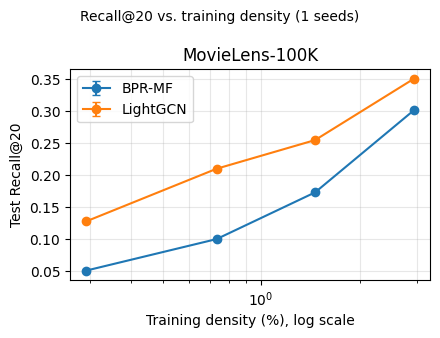

In [9]:
LABELS = {"ml100k": "MovieLens-100K", "kuairand": "KuaiRand-Pure", "mf": "BPR-MF", "lightgcn": "LightGCN"}
sweep = df[df.variant.astype(str).str.startswith("keep")]
fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.5 * len(DATASETS), 3.4), squeeze=False)
for ax, name in zip(axes[0], DATASETS):
    for model in CONFIGS:
        g = sweep[(sweep.dataset == name) & (sweep.model == model)].groupby("variant", observed=True)
        ax.errorbar(g.density.mean() * 100, g.recall.mean(), yerr=g.recall.std(ddof=0), marker="o", capsize=3, label=LABELS[model])
    ax.set_xscale("log")
    ax.set_xlabel("Training density (%), log scale")
    ax.set_ylabel("Test Recall@20")
    ax.set_title(LABELS[name]); ax.grid(alpha=0.3, which="both"); ax.legend()
fig.suptitle(f"Recall@20 vs. training density ({len(SEEDS)} seeds)", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, f"08_density_sweep{TAG}.png"), dpi=200, metadata={"Software": None})
plt.show()

In [10]:
summary.to_csv(os.path.join(RESULTS_DIR, f"08_density_sweep{TAG}_summary.csv"))
gap.to_csv(os.path.join(RESULTS_DIR, f"08_density_sweep{TAG}_gap.csv"))
print(sorted(os.listdir(RESULTS_DIR)))

['.gitkeep', '01_data_stats.json', '01_dataset_overview.csv', '01_degree_distributions.png', '01_kuairand_daily.png', '08_density_sweep_pilot.json', '08_density_sweep_pilot.png', '08_density_sweep_pilot_gap.csv', '08_density_sweep_pilot_summary.csv']
